<a href="https://colab.research.google.com/github/Glaze0/Assignment/blob/main/R22_MLOps_monitoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 30th June 2016

In [ ]:
!gdown 1iw4Lqs9pkPlu_2tEDas71xxDM-XfDpsL

Downloading...
From: https://drive.google.com/uc?id=1iw4Lqs9pkPlu_2tEDas71xxDM-XfDpsL
To: /content/taj_bookings_2015_2017.csv
100% 9.64M/9.64M [00:00<00:00, 31.8MB/s]


In [ ]:
import os, json, joblib, sklearn
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score

In [ ]:
bookings = pd.read_csv("taj_bookings_2015_2017.csv")

In [ ]:
bookings.head()

,arrival_month,hotel,country,lead_time,deposit_type,previous_cancellations,booking_changes,total_of_special_requests,required_car_parking_spaces,market_segment,customer_type,adr,adults,stays_in_week_nights,is_repeated_guest,is_canceled
0,2015-07,Resort Hotel,PRT,342,No Deposit,0,3,0,0,Direct,Transient,0.0,2,0,0,0
1,2015-07,Resort Hotel,PRT,737,No Deposit,0,4,0,0,Direct,Transient,0.0,2,0,0,0
2,2015-07,Resort Hotel,GBR,7,No Deposit,0,0,0,0,Direct,Transient,75.0,1,1,0,0
3,2015-07,Resort Hotel,GBR,13,No Deposit,0,0,0,0,Corporate,Transient,75.0,1,1,0,0
4,2015-07,Resort Hotel,GBR,14,No Deposit,0,0,1,0,Online TA,Transient,98.0,2,2,0,0


In [ ]:
print(bookings.shape)
print("arrivals from", bookings["arrival_month"].min(), "to", bookings["arrival_month"].max())

history = bookings[bookings["arrival_month"] < "2016-07"]     # everything we know on go-live night
future = bookings[bookings["arrival_month"] >= "2016-07"]     # locked data ( no acess )
print("history:", len(history), "| future:", len(future))

(119390, 16)
arrivals from 2015-07 to 2017-08
history: 49157 | future: 70233


In [ ]:
history.shape

(49157, 16)

In [ ]:
# history.head()

In [ ]:
features = [c for c in bookings.columns if c not in ["arrival_month", "is_canceled"]]   # 14 columns
number_cols = bookings[features].select_dtypes("number").columns.tolist()
text_cols = bookings[features].select_dtypes("object").columns.tolist()

def make_model(min_samples_leaf=1):                  # R22's pipeline, unchanged,
    text_steps = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
    prep = ColumnTransformer([("numbers", "passthrough", number_cols), ("text", text_steps, text_cols)])
    forest = RandomForestClassifier(min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=42)
    return Pipeline([("prep", prep), ("forest", forest)])

# 1. Evaluate

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    history[features], history["is_canceled"], test_size=0.2, random_state=42, stratify=history["is_canceled"])

model = make_model()
model.fit(X_train, y_train)
score = model.score(X_test, y_test)
print("random split:", round(score, 3))     # R22's habit

random split: 0.912


In [ ]:
old = history[history["arrival_month"] < "2016-04"]        # Jul 2015 - Mar 2016: train
recent = history[history["arrival_month"] >= "2016-04"]    # Apr - Jun 2016: the latest 3 months are the exam

model = make_model()
model.fit(old[features], old["is_canceled"])
score = model.score(recent[features], recent['is_canceled'])
print("time split:  ", round(score, 3))

time split:   0.836


In [ ]:
# how many true positive/how many predicted postive

In [ ]:
pred = model.predict(recent[features])

acc = accuracy_score(recent["is_canceled"], pred)
prec = precision_score(recent["is_canceled"], pred)        # of the bookings we flag, how many really cancel
print("accuracy", round(acc, 3), "| precision", round(prec, 3))

gate = {                                                   # written down BEFORE anyone saw a score
    "accuracy >= 80%": acc >= 0.80,
    "precision >= 85%": prec >= 0.85,
}
for check, passed in gate.items():
    print("PASS" if passed else "FAIL", "-", check)
print("DECISION:", "SHIP" if all(gate.values()) else "DO NOT SHIP")

accuracy 0.836 | precision 0.88
PASS - accuracy >= 80%
PASS - precision >= 85%
DECISION: SHIP


# 2. Ship 'Pipeline'

In [ ]:
model = make_model()
model.fit(history[features], history["is_canceled"])       # passed the exam: refit on all 12 months

joblib.dump(model, "taj_cancel_v1.joblib")                 # the WHOLE pipeline: imputer + encoder + forest


card = {                                                   # the model card: what is inside this file?
    "name": "taj_cancel", "version": "v1",
    "trained_on": "arrivals 2015-07 to 2016-06", "rows": len(history),
    "features": features,
    "exam": {"accuracy": round(acc, 3), "precision": round(prec, 3)},
    "sklearn_version": sklearn.__version__,
}
with open("taj_cancel_v1.json", "w") as f:
    json.dump(card, f, indent=2)

print("model file:", round(os.path.getsize("taj_cancel_v1.joblib") / 1e6), "MB")

model file: 91 MB


In [ ]:
# Practice: the hotel's IT team says a model file must be under 50 MB. Ours is 91 MB. Try two fixes:
#   a) same model, squeezed:   joblib.dump(model, "taj_cancel_v1_small.joblib", compress=3)
#   b) smaller trees (R15):    make_model(min_samples_leaf=5), fitted on history, then dumped
# Check each size with:        round(os.path.getsize("taj_cancel_v1_small.joblib") / 1e6)
# For (b): it is a different model. Does it still pass the gate? (Use make_model(min_samples_leaf=5) in §1.)

### Backend team

In [ ]:
# ---------- the nightly job: a separate program, on the hotel's server, every night ----------

job_model = joblib.load("taj_cancel_v1.joblib")


# real future data .. 4am..
july = future[future["arrival_month"] == "2016-07"].copy()      # tonight: every booking arriving in July
july["cancel_prob"] = job_model.predict_proba(july[features])[:, 1]
print("July bookings:", len(july), "| flagged 'will cancel':", (july["cancel_prob"] >= 0.5).sum())

July bookings: 4572 | flagged 'will cancel': 1120


In [ ]:
july.to_csv("scores_2016-07.csv", index=False)               # the job's output: a table the revenue team opens tomorrow
july.sort_values("cancel_prob", ascending=False)[["hotel", "lead_time", "deposit_type", "market_segment", "adr", "cancel_prob"]].head()

,hotel,lead_time,deposit_type,market_segment,adr,cancel_prob
51964,City Hotel,384,Non Refund,Groups,65.0,1.0
49194,City Hotel,179,Non Refund,Groups,65.0,1.0
49195,City Hotel,179,Non Refund,Groups,65.0,1.0
49197,City Hotel,179,Non Refund,Groups,65.0,1.0
50069,City Hotel,365,Non Refund,Groups,62.0,1.0


In [ ]:
# 4am
# extract all 24hours bookings.
# batch to job_model.predict_proba(july[features])[:, 1]
# create a .csv / report.


# 3. Guardrails (Input)

In [ ]:
def predict_booking(booking):
    pred = job_model.predict_proba(pd.DataFrame([booking])[features])[0, 1]
    return {"status": "ok", "cancel_prob": round(float(pred), 2), "model": "v1"}

In [ ]:
normal = future.iloc[1][features].to_dict()
predict_booking(normal)

{'status': 'ok', 'cancel_prob': 0.22, 'model': 'v1'}

In [ ]:
normal

{'hotel': 'Resort Hotel',
 'country': 'IND',
 'lead_time': 62,
 'deposit_type': 'No Deposit',
 'previous_cancellations': 0,
 'booking_changes': 0,
 'total_of_special_requests': 0,
 'required_car_parking_spaces': 0,
 'market_segment': 'Online TA',
 'customer_type': 'Transient',
 'adr': 220.0,
 'adults': 2,
 'stays_in_week_nights': 2,
 'is_repeated_guest': 0}

In [ ]:
negative = future[future["adr"] < 0].iloc[0][features].to_dict()
negative

{'hotel': 'Resort Hotel',
 'country': 'GBR',
 'lead_time': 195,
 'deposit_type': 'No Deposit',
 'previous_cancellations': 0,
 'booking_changes': 2,
 'total_of_special_requests': 0,
 'required_car_parking_spaces': 0,
 'market_segment': 'Groups',
 'customer_type': 'Transient-Party',
 'adr': -6.38,
 'adults': 2,
 'stays_in_week_nights': 6,
 'is_repeated_guest': 1}

In [ ]:
predict_booking(negative)

{'status': 'ok', 'cancel_prob': 0.0, 'model': 'v1'}

In [ ]:
RULES = {"adr": (0, 1000), "lead_time": (0, 750), "adults": (1, 10)}

def check(booking):
    problems = []
    for col in features:
        if col not in booking:
            problems.append("missing column: " + col)
    for col, (low, high) in RULES.items():
        if col in booking and not low <= booking[col] <= high:
            problems.append(f"{col} = {booking[col]} is outside {low} to {high}")
    return problems


def predict_booking(booking):
    problems = check(booking)
    if problems:
        return {"status": "rejected", "problems": problems}

    pred = job_model.predict_proba(pd.DataFrame([booking])[features])[0, 1]
    return {"status": "ok", "cancel_prob": round(float(pred), 2), "model": "v1"}

In [ ]:
predict_booking(negative)

{'status': 'rejected', 'problems': ['adr = -6.38 is outside 0 to 1000']}

In [ ]:
normal['price'] = normal.pop('adr')
normal

{'hotel': 'Resort Hotel',
 'country': 'IND',
 'lead_time': 62,
 'deposit_type': 'No Deposit',
 'previous_cancellations': 0,
 'booking_changes': 0,
 'total_of_special_requests': 0,
 'required_car_parking_spaces': 0,
 'market_segment': 'Online TA',
 'customer_type': 'Transient',
 'adults': 2,
 'stays_in_week_nights': 2,
 'is_repeated_guest': 0,
 'price': 220.0}

In [ ]:
predict_booking(normal)

{'status': 'rejected', 'problems': ['missing column: adr']}

# 4. Monitoring

In [ ]:
def psi(train_col, new_col):     # how far a column has moved since training
    if train_col.dtype == object:                                       # text: share of each category
        a = train_col.value_counts(normalize=True)
        b = new_col.value_counts(normalize=True).reindex(a.index).fillna(0)
    else:                                                               # numbers: 10 equal buckets of training values
        edges = np.unique(np.quantile(train_col, np.linspace(0, 1, 11)))
        edges[0], edges[-1] = -np.inf, np.inf
        a = pd.Series(np.histogram(train_col, edges)[0] / len(train_col))
        b = pd.Series(np.histogram(new_col, edges)[0] / len(new_col))

    a, b = a.clip(lower=1e-4).values, b.clip(lower=1e-4).values
    return round(float(np.sum((b - a) * np.log(b / a))), 2)

In [ ]:
rows = []
for month, batch in future.groupby("arrival_month"):
    pred = job_model.predict(batch[features])
    rows.append({
        "month": month,
        "price_psi": psi(history["adr"], batch["adr"]),                               # 1. inputs       (tonight)
        "segment_psi": psi(history["market_segment"], batch["market_segment"]),       # 1. inputs       (tonight)
        "flagged": pred.mean(),                                                       # 2. predictions  (tonight)
        "cancelled": batch["is_canceled"].mean(),                                     # 3. the truth    (after arrival)
        "accuracy": accuracy_score(batch["is_canceled"], pred),                       # 3. performance  (after arrival)
    })
report = pd.DataFrame(rows).set_index("month").round(2)
report

,price_psi,segment_psi,flagged,cancelled,accuracy
month,,,,,
2016-07,0.91,0.34,0.24,0.33,0.83
2016-08,1.34,0.58,0.23,0.36,0.77
2016-09,0.60,0.05,0.27,0.37,0.83
2016-10,0.14,0.05,0.23,0.41,0.77
2016-11,0.16,0.10,0.24,0.37,0.81
2016-12,0.08,0.29,0.19,0.36,0.76
2017-01,0.36,0.34,0.23,0.34,0.80
2017-02,0.24,0.25,0.19,0.33,0.77
2017-03,0.18,0.13,0.24,0.34,0.80


In [ ]:
report["input_alarm"] = (report["price_psi"] > 0.25) | (report["segment_psi"] > 0.25)    # rules written on go-live night
report["accuracy_alarm"] = report["accuracy"] < 0.75
report[["price_psi", "segment_psi", "input_alarm", "accuracy", "accuracy_alarm"]]

,price_psi,segment_psi,input_alarm,accuracy,accuracy_alarm
month,,,,,
2016-07,0.91,0.34,True,0.83,False
2016-08,1.34,0.58,True,0.77,False
2016-09,0.60,0.05,True,0.83,False
2016-10,0.14,0.05,False,0.77,False
2016-11,0.16,0.10,False,0.81,False
2016-12,0.08,0.29,True,0.76,False
2017-01,0.36,0.34,True,0.80,False
2017-02,0.24,0.25,False,0.77,False
2017-03,0.18,0.13,False,0.80,False


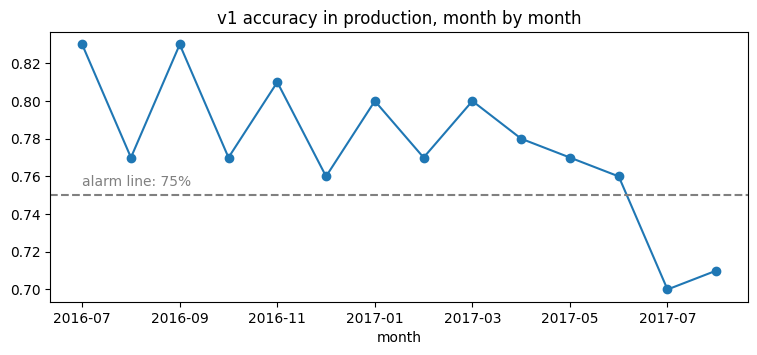

In [ ]:
ax = report["accuracy"].plot(marker="o", figsize=(9, 3.5), title="v1 accuracy in production, month by month")
ax.axhline(0.75, color="gray", linestyle="--")
ax.text(0, 0.755, "alarm line: 75%", color="gray");

# 5. Retrain the model on total updated new dataset.